<div align="center">

# PulsoVision · CNN de Prioridade de Avaliação por Foto da Pele
**Disciplina 07: Redes Neurais Artificiais, Deep Learning e Algoritmos Genéticos**<br>
Global Solution 2026.2 — FIAP · CitizenTech<br>
Arquivo: `07-redes-neurais/cnn_prioridade_pele.ipynb`

*"A porta de entrada da saúde pra quem não tem médico."*

</div>

**Resumo:** uma rede neural convolucional (CNN) recebe a **foto de uma lesão de pele tirada com celular** e diz se aquela lesão **merece avaliação presencial com prioridade**, como um dermatologista decidiria ao pedir uma biópsia. A rede **não dá diagnóstico**: ela nunca diz o nome de uma doença. Só orienta o PulsoVision a subir a cor da triagem e encaminhar a pessoa para a UBS.

Base: **PAD-UFES-20** (UFES), com 2.298 fotos reais de celular, validada pela professora. São comparadas quatro configurações: uma CNN treinada do zero, a VGG16 da aula, a MobileNetV2 com dropout e data augmentation, e a MobileNetV2 com fine-tuning. Todas usam early stopping.

**Rode com GPU, no Google Colab ou no Kaggle.** No Colab: menu **Ambiente de execução → Alterar o tipo de ambiente de execução → GPU T4**, depois **Executar tudo**. No Kaggle: **Settings → Accelerator → GPU T4**, depois **Run All**. Leva cerca de 20 a 30 minutos; o notebook baixa a base sozinho. *Os resultados salvos neste arquivo vêm de uma execução no Kaggle com GPU T4.*

**Integrantes:**
- Tiago Thomaz Cesaro
- Bruno Henrique Ferreira Ambrosio
- Lucas Maximo dos Santos

## 1. Problema e aplicação

**Problema.** Muita gente convive com uma "pinta", uma ferida que não cicatriza ou uma mancha que mudou, sem saber se aquilo merece uma consulta. Na periferia e no interior, a espera por um dermatologista é longa, e a lesão que precisava de atenção chega tarde.

**Público.** Moradores de periferia e interior que dependem do SUS e usam o PulsoVision pelo celular.

**Como a rede neural contribui.** O cidadão fotografa a lesão no app. A CNN olha a foto e responde se ela tem o aspecto das lesões que **um especialista mandaria investigar**. Quando tem, o PulsoVision sobe a cor da triagem para **amarelo** e orienta a procurar a UBS com a lesão. Quando não tem, a pessoa **não é tranquilizada**: recebe a orientação de voltar se a lesão crescer, mudar de cor, coçar ou sangrar.

| | Definição |
|---|---|
| **Entrada** | Uma foto colorida da lesão, tirada com celular (redimensionada para 224 × 224 pixels) |
| **Saída** | Uma pontuação de 0 a 1 e a decisão: **avaliar com prioridade** ou **sem sinal de alerta na foto** |
| **O que a rede NÃO faz** | Não diz o nome de nenhuma doença, não descarta nada e não substitui o exame presencial |

In [1]:
import json
import os
import shutil
import time
import warnings
import zipfile
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from PIL import Image, ImageOps
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedGroupKFold
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore", category=UserWarning)
SEMENTE = 2026
keras.utils.set_random_seed(SEMENTE)
sns.set_theme(style="whitegrid", context="notebook")
Path("figuras").mkdir(exist_ok=True)

TAMANHO = 224          # lado da imagem de entrada (pixels)
LOTE = 32              # batch size
EPOCAS_MAX = 30        # teto; o early stopping para antes
PESOS = "imagenet"     # pesos pré-treinados das redes de transfer learning

gpus = tf.config.list_physical_devices("GPU")
print(f"TensorFlow {tf.__version__} | GPU: {gpus[0].name if gpus else 'NÃO ENCONTRADA'}")
if not gpus:
    print("Sem GPU o treino fica muito lento. No Colab: Ambiente de execução > Alterar o tipo > GPU T4.")

TensorFlow 2.21.0 | GPU: /physical_device:GPU:0


## 2. A base de dados: PAD-UFES-20

**Fonte.** Pacheco, A. G. C. *et al.* "PAD-UFES-20: a skin lesion dataset composed of patient data and clinical images collected from smartphones". *Data in Brief*, v. 32, 2020. DOI: 10.1016/j.dib.2020.106221. Os dados estão no Mendeley Data (DOI 10.17632/zr7vgbcyr2.1), com licença CC BY 4.0. O notebook baixa a base sozinho: tenta primeiro o Mendeley Data e, se o servidor recusar, usa a cópia pública da mesma base no Kaggle. Só se as duas falharem ele pede o upload do zip.

**Características:**
- **2.298 fotos** de **1.641 lesões** de **1.373 pacientes**, tiradas com **celular** em formato PNG e em resoluções diferentes, conforme o aparelho;
- coletadas no **Programa de Assistência Dermatológica e Cirúrgica (PAD) da UFES**, que atende de graça principalmente pessoas de baixa renda;
- cada foto vem com até 22 informações clínicas, entre elas o identificador do paciente e se a lesão **foi biopsiada**.

**Por que é adequada:**
1. É **brasileira**.
2. As fotos são de **celular**, como as que o cidadão mandaria pelo app, e não de dermatoscópio de consultório.
3. O público é o **mesmo do PulsoVision**.
4. Tem o registro de uma **decisão clínica**: se o especialista mandou ou não a lesão para biópsia. Esse registro serve de alvo sem que a rede precise diagnosticar.

**Alvo (saída da rede).** `avaliar_prioridade` = 1 quando o dermatologista **pediu biópsia** da lesão, ou seja, julgou que ela precisava ser investigada, e 0 quando não pediu. Segundo os autores, cerca de 58% das lesões foram biopsiadas, incluindo todos os cânceres de pele da base. O diagnóstico registrado na base **não entra na rede**: aparece só na seção 7, para conferir a segurança do modelo.

In [2]:
MENDELEY_API = "https://data.mendeley.com/public-api/datasets/zr7vgbcyr2/files?folder_id=root&version=1"
KAGGLE_ESPELHO = "mahdavi1202/skin-cancer"   # cópia pública da mesma PAD-UFES-20 no Kaggle
PASTA_DADOS = Path("pad_ufes_20")
NAVEGADOR = {"User-Agent": "Mozilla/5.0 (PulsoVision - FIAP Global Solution 2026.2)"}


def base_completa(pasta: Path) -> bool:
    """A base está pronta quando há o metadata.csv e pelo menos 2.000 fotos."""
    return pasta.exists() and any(pasta.rglob("metadata.csv")) and sum(1 for _ in pasta.rglob("*.png")) >= 2000


def extrair_zips(pasta: Path) -> None:
    """Extrai todos os zips da pasta, inclusive os que aparecem dentro de outros zips."""
    while True:
        pacotes = [p for p in pasta.rglob("*") if p.is_file() and p.suffix.lower() not in {".png", ".csv"}
                   and zipfile.is_zipfile(p)]
        if not pacotes:
            return
        for pacote in pacotes:
            with zipfile.ZipFile(pacote) as z:
                z.extractall(pacote.parent)
            pacote.unlink()


def links_mendeley(no, nome=None):
    """Percorre a resposta da API do Mendeley e devolve pares (nome do arquivo, link de download)."""
    if isinstance(no, dict):
        nome = no.get("filename", nome)
        if isinstance(no.get("download_url"), str):
            yield nome or "arquivo.zip", no["download_url"]
        for valor in no.values():
            yield from links_mendeley(valor, nome)
    elif isinstance(no, list):
        for valor in no:
            yield from links_mendeley(valor, nome)


def via_mendeley(destino: Path) -> Path:
    """Fonte oficial: lista os arquivos pela API pública do Mendeley Data e baixa cada um."""
    pedido = urllib.request.Request(MENDELEY_API, headers=NAVEGADOR)
    with urllib.request.urlopen(pedido, timeout=60) as resposta:
        links = dict(links_mendeley(json.load(resposta)))
    if not links:
        raise RuntimeError("a API não devolveu links de download")
    destino.mkdir(exist_ok=True)
    for nome, url in links.items():
        print(f"  baixando {nome}...")
        pedido = urllib.request.Request(url, headers=NAVEGADOR)
        with urllib.request.urlopen(pedido, timeout=600) as resposta, open(destino / Path(nome).name, "wb") as saida:
            shutil.copyfileobj(resposta, saida, length=1 << 20)
    extrair_zips(destino)
    return destino


def via_kaggle(_destino: Path) -> Path:
    """Espelho público no Kaggle; o kagglehub já vem instalado no Colab e baixa dados públicos sem login."""
    import kagglehub
    pasta = Path(kagglehub.dataset_download(KAGGLE_ESPELHO))
    extrair_zips(pasta)
    return pasta


def via_upload(destino: Path) -> Path:
    """Último recurso: usa um zip da base enviado à mão para a pasta do notebook."""
    destino.mkdir(exist_ok=True)
    enviados = [p for p in Path(".").glob("*.zip") if zipfile.is_zipfile(p)]
    if not enviados:
        try:
            from google.colab import files
            print("  Envie o zip da PAD-UFES-20 (baixado em data.mendeley.com/datasets/zr7vgbcyr2/1):")
            enviados = [Path(nome) for nome in files.upload()]
        except ImportError:
            raise RuntimeError("coloque o zip da PAD-UFES-20 na mesma pasta do notebook")
    for pacote in enviados:
        shutil.move(str(pacote), destino / pacote.name)
    extrair_zips(destino)
    return destino


def obter_base(destino: Path) -> Path:
    """Tenta as fontes em ordem e devolve a pasta onde a base ficou."""
    if base_completa(destino):
        print(f"Base já disponível em {destino}/")
        return destino
    fontes = [("Mendeley Data (fonte oficial)", via_mendeley),
              ("espelho público no Kaggle", via_kaggle),
              ("upload manual", via_upload)]
    for rotulo, baixar in fontes:
        print(f"Obtendo a PAD-UFES-20 pelo {rotulo}...")
        try:
            pasta = baixar(destino)
        except Exception as erro:
            print(f"  não deu certo ({type(erro).__name__}: {erro}); tentando a próxima fonte.")
            continue
        if base_completa(pasta):
            print(f"  ok: {sum(1 for _ in pasta.rglob('*.png'))} imagens em {pasta}/")
            return pasta
        print("  a fonte respondeu, mas a base veio incompleta; tentando a próxima.")
    raise RuntimeError("Nenhuma fonte entregou a base completa. Veja as mensagens acima.")


PASTA_DADOS = obter_base(PASTA_DADOS)
caminho_meta = next(PASTA_DADOS.rglob("metadata.csv"))
fotos = {p.name: p for p in PASTA_DADOS.rglob("*.png")}
print(f"Metadados: {caminho_meta} | fotos encontradas: {len(fotos)}")

Obtendo a PAD-UFES-20 pelo Mendeley Data (fonte oficial)...
  baixando metadata.csv...
  a fonte respondeu, mas a base veio incompleta; tentando a próxima.
Obtendo a PAD-UFES-20 pelo espelho público no Kaggle...
Using Colab cache for faster access to the 'skin-cancer' dataset.
  ok: 2298 imagens em /kaggle/input/skin-cancer/
Metadados: /kaggle/input/skin-cancer/metadata.csv | fotos encontradas: 2298


Fotos com metadados: 2298 | pacientes: 1373 | lesões: 1641
Avaliar com prioridade (biopsiadas): 1342 (58.4%)
Fotos por paciente: média 1.67, máximo 10


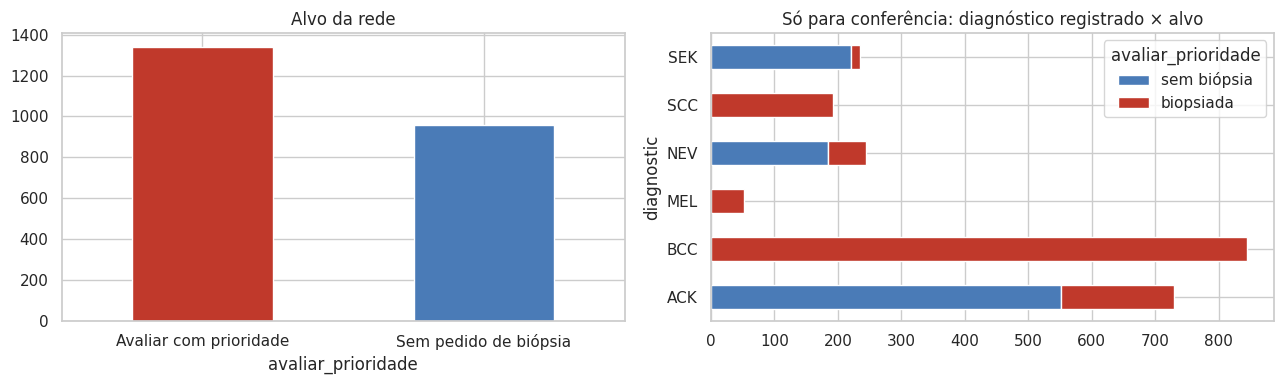

In [3]:
meta = pd.read_csv(caminho_meta)
coluna_biopsia = next(c for c in meta.columns if c.lower().startswith("biops"))
meta["arquivo"] = meta["img_id"].astype(str).map(lambda n: n if n.lower().endswith(".png") else f"{n}.png")
meta = meta[meta["arquivo"].isin(fotos)].reset_index(drop=True)
meta["avaliar_prioridade"] = meta[coluna_biopsia].astype(str).str.lower().isin(["true", "1", "yes", "sim"]).astype(int)

print(f"Fotos com metadados: {len(meta)} | pacientes: {meta['patient_id'].nunique()} | lesões: {meta['lesion_id'].nunique()}")
print(f"Avaliar com prioridade (biopsiadas): {meta['avaliar_prioridade'].sum()} "
      f"({100 * meta['avaliar_prioridade'].mean():.1f}%)")
print(f"Fotos por paciente: média {meta.groupby('patient_id').size().mean():.2f}, "
      f"máximo {meta.groupby('patient_id').size().max()}")

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
meta["avaliar_prioridade"].map({1: "Avaliar com prioridade", 0: "Sem pedido de biópsia"}).value_counts().plot.bar(
    ax=eixos[0], color=["#c0392b", "#4a7bb7"])
eixos[0].set_title("Alvo da rede")
eixos[0].tick_params(axis="x", rotation=0)
pd.crosstab(meta["diagnostic"], meta["avaliar_prioridade"]).rename(
    columns={0: "sem biópsia", 1: "biopsiada"}).plot.barh(ax=eixos[1], stacked=True, color=["#4a7bb7", "#c0392b"])
eixos[1].set_title("Só para conferência: diagnóstico registrado × alvo")
plt.tight_layout()
plt.savefig("figuras/01_alvo.png", dpi=150)
plt.show()

**Leitura:**
- O alvo é razoavelmente **equilibrado** (cerca de 58% × 42%). Mesmo assim, o treino usa pesos por classe (`class_weight`), para nenhuma classe dominar.
- Todas as lesões com diagnóstico de câncer foram biopsiadas, como dizem os autores. Algumas lesões não malignas também foram, porque o especialista quis investigar. É exatamente esse comportamento que a rede aprende: **o que vale investigar**, e não qual é a doença.
- Há pacientes com várias fotos. Se o mesmo paciente aparecer no treino e no teste, a rede pode "reconhecer a pessoa" em vez da lesão. Por isso a divisão é feita **por paciente** (seção 3).

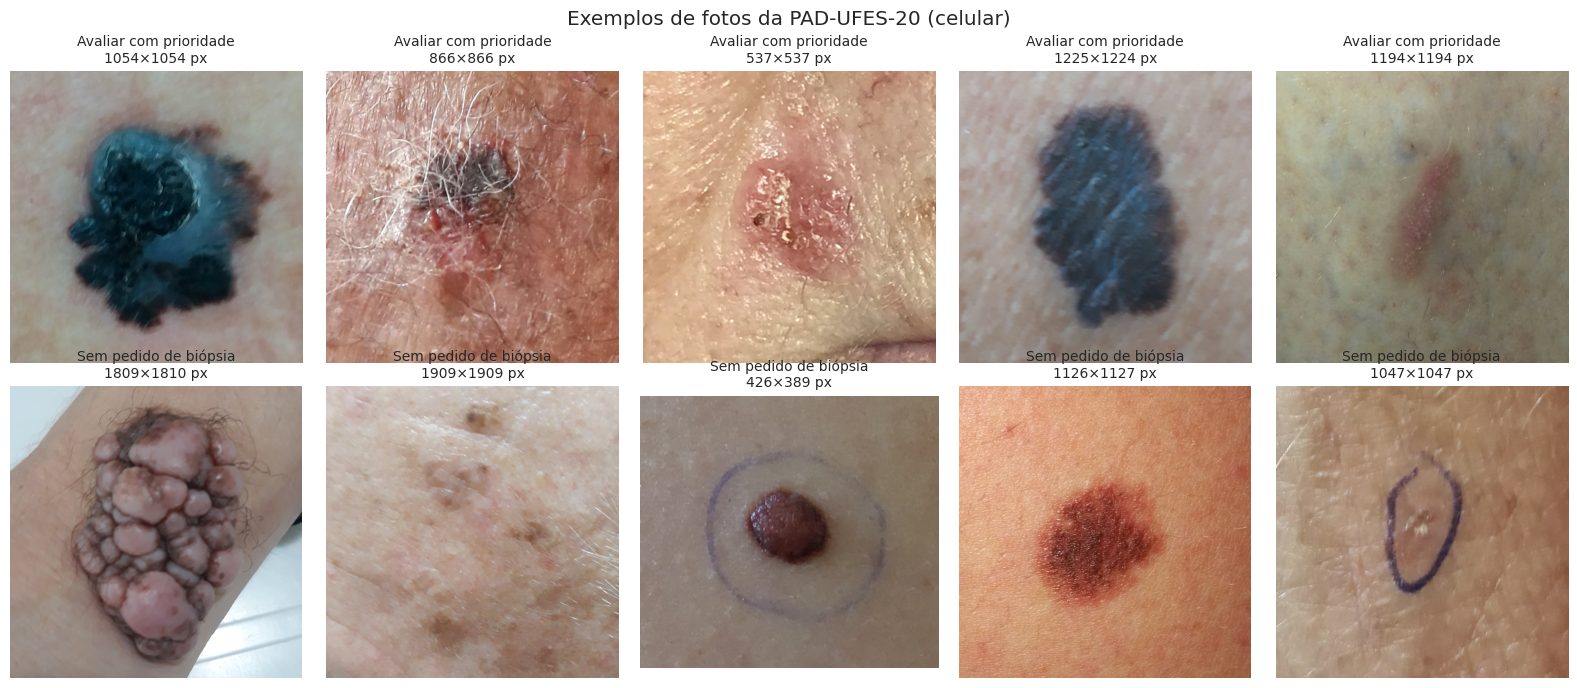

In [4]:
exemplos = pd.concat([meta[meta["avaliar_prioridade"] == 1].sample(5, random_state=SEMENTE),
                      meta[meta["avaliar_prioridade"] == 0].sample(5, random_state=SEMENTE)])
fig, eixos = plt.subplots(2, 5, figsize=(16, 7))
for eixo, (_, linha) in zip(eixos.ravel(), exemplos.iterrows()):
    foto = Image.open(fotos[linha["arquivo"]])
    eixo.imshow(foto)
    eixo.set_title(("Avaliar com prioridade" if linha["avaliar_prioridade"] else "Sem pedido de biópsia")
                   + f"\n{foto.size[0]}×{foto.size[1]} px", fontsize=10)
    eixo.axis("off")
plt.suptitle("Exemplos de fotos da PAD-UFES-20 (celular)")
plt.tight_layout()
plt.savefig("figuras/02_exemplos.png", dpi=120)
plt.show()

## 3. Preparação dos dados

**Decisões:**
1. **Tamanho único de 224 × 224 pixels.** É o tamanho que as redes pré-treinadas esperam. As fotos têm proporções diferentes, então cada uma é **recortada no centro** antes de reduzir (`ImageOps.fit`), para não distorcer a lesão. As imagens ficam guardadas na memória como inteiros de 0 a 255, e a normalização de cada rede é feita **dentro do modelo**.
2. **Divisão por paciente**, com cerca de 70% para treino, 15% para validação e 15% para teste, usando `StratifiedGroupKFold`. Nenhum paciente aparece em dois conjuntos, e a proporção do alvo fica parecida nos três.
    - A **validação** serve para o early stopping, para comparar configurações e para escolher o corte.
    - O **teste** só é usado uma vez, no fim.
3. **Data augmentation** (giros, espelhamento, zoom e contraste) só nas configurações que pedem, e só durante o treino. Assim a rede vê a mesma lesão de jeitos diferentes, como acontece com fotos de celular reais.
4. **Pesos por classe** (`class_weight`), para equilibrar o erro entre as duas classes.

In [5]:
def carregar(arquivo: str) -> np.ndarray:
    foto = Image.open(fotos[arquivo]).convert("RGB")
    return np.asarray(ImageOps.fit(foto, (TAMANHO, TAMANHO), Image.Resampling.BILINEAR), dtype=np.uint8)


inicio = time.time()
with ThreadPoolExecutor(max_workers=8) as executor:
    imagens = np.stack(list(executor.map(carregar, meta["arquivo"])))
rotulos = meta["avaliar_prioridade"].to_numpy()
print(f"{imagens.shape[0]} imagens {imagens.shape[1:]} carregadas em {time.time() - inicio:.0f} s "
      f"({imagens.nbytes / 1e6:.0f} MB na memória)")

2298 imagens (224, 224, 3) carregadas em 82 s (346 MB na memória)


In [6]:
grupos = meta["patient_id"].to_numpy()
dobras = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEMENTE)
partes = [teste for _, teste in dobras.split(imagens, rotulos, grupos)]
idx_teste = np.concatenate(partes[:1])
idx_val = np.concatenate(partes[1:2])
idx_treino = np.concatenate(partes[2:])

X_treino, y_treino = imagens[idx_treino], rotulos[idx_treino]
X_val, y_val = imagens[idx_val], rotulos[idx_val]
X_teste, y_teste = imagens[idx_teste], rotulos[idx_teste]

for nome, idx in [("treino", idx_treino), ("validação", idx_val), ("teste", idx_teste)]:
    print(f"{nome:<10} {len(idx):>5} fotos | {meta.loc[idx, 'patient_id'].nunique():>4} pacientes | "
          f"{100 * rotulos[idx].mean():.1f}% avaliar com prioridade")
comuns = (set(grupos[idx_treino]) & set(grupos[idx_teste])) | (set(grupos[idx_treino]) & set(grupos[idx_val]))
print(f"Pacientes em mais de um conjunto: {len(comuns)}")

pesos = {c: len(y_treino) / (2 * np.sum(y_treino == c)) for c in (0, 1)}
print("Pesos por classe:", {k: round(v, 3) for k, v in pesos.items()})

treino      1622 fotos |  983 pacientes | 58.5% avaliar com prioridade
validação    327 fotos |  192 pacientes | 56.0% avaliar com prioridade
teste        349 fotos |  198 pacientes | 60.2% avaliar com prioridade
Pacientes em mais de um conjunto: 0
Pesos por classe: {0: np.float64(1.205), 1: np.float64(0.855)}


## 4. Arquitetura da rede neural

Foram escolhidas **CNNs (redes convolucionais)**, porque a entrada é uma imagem. As camadas convolucionais procuram padrões locais (bordas, cores, texturas e formas) e os combinam em padrões cada vez mais complexos. A parte final, densa, transforma esses padrões numa pontuação de 0 a 1 por meio da função **sigmoide**.

Com só 2.298 fotos, treinar uma CNN grande do zero tende ao overfitting. Por isso a principal estratégia é o **transfer learning**: aproveitar uma rede que já aprendeu a "ver" em 1,4 milhão de imagens (ImageNet) e treinar só a parte final para a nossa tarefa, como na aula com a VGG16.

| Config. | Arquitetura | Regularização | Por que entra |
|---|---|---|---|
| **C1** | CNN simples **do zero**: 3 blocos Conv + MaxPool, GlobalAveragePooling, Dense 64 | nenhuma | Referência: quanto se consegue sem transfer learning |
| **C2** | **VGG16** congelada (ImageNet) + Flatten + Dense 128 | nenhuma | A abordagem da aula, servindo de base de comparação |
| **C3** | **MobileNetV2** congelada + GlobalAveragePooling + **Dropout 0,3** | dropout + **data augmentation** | Rede leve, feita para celular, com regularização |
| **C4** | C3 + **fine-tuning** das últimas 30 camadas da MobileNetV2, com learning rate de 10⁻⁵ | dropout + augmentation | Ajusta a rede pré-treinada às fotos de pele |

Todas usam **early stopping**, que monitora a AUC na validação (paciência de 5 épocas) e recupera os melhores pesos.

In [7]:
def lotes(X, y, embaralhar=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y.astype("float32")))
    if embaralhar:
        ds = ds.shuffle(len(X), seed=SEMENTE)
    return ds.batch(LOTE).map(lambda a, b: (tf.cast(a, tf.float32), b)).prefetch(tf.data.AUTOTUNE)


treino_ds, val_ds = lotes(X_treino, y_treino, embaralhar=True), lotes(X_val, y_val)

aumento = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
], name="data_augmentation")


def compilar(modelo, taxa):
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=taxa), loss="binary_crossentropy",
                   metrics=[keras.metrics.AUC(name="auc"), keras.metrics.BinaryAccuracy(name="acuracia"),
                            keras.metrics.Recall(name="recall")])
    return modelo


historicos, resultados, modelos = {}, {}, {}


def treinar(nome, modelo, taxa, epocas=EPOCAS_MAX, paciencia=5):
    compilar(modelo, taxa)
    parada = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=paciencia,
                                           restore_best_weights=True)
    inicio = time.time()
    h = modelo.fit(treino_ds, validation_data=val_ds, epochs=epocas, class_weight=pesos,
                   callbacks=[parada], verbose=2)
    historicos[nome], modelos[nome] = h.history, modelo
    melhor = int(np.argmax(h.history["val_auc"]))
    resultados[nome] = {"épocas rodadas": len(h.history["loss"]), "melhor época": melhor + 1,
                        "AUC treino": h.history["auc"][melhor], "AUC validação": h.history["val_auc"][melhor],
                        "perda validação": h.history["val_loss"][melhor],
                        "minutos": (time.time() - inicio) / 60, "taxa de aprendizado": taxa}
    print(f"\n{nome}: melhor AUC de validação {resultados[nome]['AUC validação']:.3f} na época {melhor + 1}")
    return modelo

## 5. Treinamento

| Parâmetro | Valor | Justificativa |
|---|---|---|
| Função de perda | entropia cruzada binária | Saída de uma pontuação de 0 a 1 (sigmoide) |
| Otimizador | Adam | Ajusta o passo de cada peso; é o padrão visto em aula |
| Learning rate | 10⁻³ (C1 a C3) e 10⁻⁵ (C4) | O fine-tuning usa um passo 100 vezes menor, para não destruir o que a rede pré-treinada já sabe |
| Batch size | 32 | Cabe na memória da GPU T4 com folga |
| Épocas | até 30, com early stopping (paciência de 5) | Para quando a AUC de validação deixa de melhorar |
| Métricas | AUC, acurácia e recall | A AUC não depende do corte; o recall mede quantas lesões que precisavam de avaliação foram pegas |

### C1: CNN simples treinada do zero

In [8]:
entrada = keras.Input(shape=(TAMANHO, TAMANHO, 3))
x = layers.Rescaling(1 / 255)(entrada)
for filtros in (32, 64, 128):
    x = layers.Conv2D(filtros, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D(2)(x)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(64, activation="relu")(x)
saida = layers.Dense(1, activation="sigmoid")(x)
modelo_c1 = treinar("C1 · CNN do zero", keras.Model(entrada, saida, name="cnn_do_zero"), taxa=1e-3)

Epoch 1/30
51/51 - 30s - 590ms/step - acuracia: 0.4784 - auc: 0.4767 - loss: 0.6953 - recall: 0.4457 - val_acuracia: 0.5596 - val_auc: 0.5358 - val_loss: 0.6926 - val_recall: 1.0000
Epoch 2/30
51/51 - 3s - 55ms/step - acuracia: 0.5129 - auc: 0.4889 - loss: 0.6940 - recall: 0.6185 - val_acuracia: 0.4465 - val_auc: 0.5413 - val_loss: 0.6936 - val_recall: 0.0164
Epoch 3/30
51/51 - 3s - 58ms/step - acuracia: 0.4649 - auc: 0.4833 - loss: 0.6953 - recall: 0.3530 - val_acuracia: 0.4465 - val_auc: 0.5149 - val_loss: 0.6939 - val_recall: 0.0109
Epoch 4/30
51/51 - 3s - 56ms/step - acuracia: 0.5068 - auc: 0.5120 - loss: 0.6933 - recall: 0.4668 - val_acuracia: 0.4404 - val_auc: 0.5750 - val_loss: 0.6945 - val_recall: 0.0000e+00
Epoch 5/30
51/51 - 3s - 55ms/step - acuracia: 0.4797 - auc: 0.5242 - loss: 0.6940 - recall: 0.2666 - val_acuracia: 0.5046 - val_auc: 0.6289 - val_loss: 0.6930 - val_recall: 0.1366
Epoch 6/30
51/51 - 3s - 55ms/step - acuracia: 0.5117 - auc: 0.5557 - loss: 0.6911 - recall: 0.

### C2: VGG16 congelada, como na aula

In [9]:
vgg = keras.applications.VGG16(weights=PESOS, include_top=False, input_shape=(TAMANHO, TAMANHO, 3))
vgg.trainable = False
entrada = keras.Input(shape=(TAMANHO, TAMANHO, 3))
x = layers.Lambda(keras.applications.vgg16.preprocess_input, name="preprocess_vgg16")(entrada)
x = vgg(x, training=False)
x = layers.Flatten()(x)
x = layers.Dense(128, activation="relu")(x)
saida = layers.Dense(1, activation="sigmoid")(x)
modelo_c2 = treinar("C2 · VGG16 congelada", keras.Model(entrada, saida, name="vgg16_congelada"), taxa=1e-3)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/30
51/51 - 54s - 1s/step - acuracia: 0.5210 - auc: 0.6410 - loss: 2.8303 - recall: 0.3235 - val_acuracia: 0.6147 - val_auc: 0.7941 - val_loss: 0.6706 - val_recall: 0.3607
Epoch 2/30
51/51 - 9s - 173ms/step - acuracia: 0.7423 - auc: 0.8624 - loss: 0.5277 - recall: 0.6438 - val_acuracia: 0.7401 - val_auc: 0.8160 - val_loss: 0.5292 - val_recall: 0.7268
Epoch 3/30
51/51 - 9s - 177ms/step - acuracia: 0.8533 - auc: 0.9316 - loss: 0.3429 - recall: 0.8293 - val_acuracia: 0.7278 - val_auc: 0.8183 - val_loss: 0.6279 - val_recall: 0.5792
Epoch 4/30
51/51 - 9s - 176ms/step - acuracia: 0.9254 - auc: 0.9776 - loss: 0.2037 - recall: 0.9136 - val_acuracia: 0.7431 - val_auc: 0.8318 - val_loss: 0.6059 - val_recall: 0.7760
Epoch 5/30
51/51 - 9s - 174ms/step - acuracia: 0.9649 - auc: 0.9956 - loss: 0.1101 - recall: 0.9526 - val_acuracia: 0.7584 - val_auc: 0.8363 - val_loss: 0.6199 - val_recall: 0.7486
Epoch 6/30
51/51 - 9s - 170ms/step - acuracia:

### C3: MobileNetV2 congelada, com dropout e data augmentation

In [10]:
def mobilenet_c3():
    base = keras.applications.MobileNetV2(weights=PESOS, include_top=False, input_shape=(TAMANHO, TAMANHO, 3))
    base.trainable = False
    entrada = keras.Input(shape=(TAMANHO, TAMANHO, 3))
    x = aumento(entrada)
    x = layers.Rescaling(1 / 127.5, offset=-1)(x)   # mesma normalização da MobileNetV2 (-1 a 1)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    saida = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(entrada, saida, name="mobilenetv2"), base


modelo_c3, base_c3 = mobilenet_c3()
_ = treinar("C3 · MobileNetV2 + dropout + augmentation", modelo_c3, taxa=1e-3)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/30
51/51 - 17s - 338ms/step - acuracia: 0.5882 - auc: 0.6226 - loss: 0.7228 - recall: 0.5827 - val_acuracia: 0.6758 - val_auc: 0.7164 - val_loss: 0.6242 - val_recall: 0.6503
Epoch 2/30
51/51 - 4s - 87ms/step - acuracia: 0.6843 - auc: 0.7557 - loss: 0.5970 - recall: 0.6723 - val_acuracia: 0.6972 - val_auc: 0.7648 - val_loss: 0.5765 - val_recall: 0.7213
Epoch 3/30
51/51 - 4s - 75ms/step - acuracia: 0.7090 - auc: 0.7834 - loss: 0.5685 - recall: 0.6976 - val_acuracia: 0.7309 - val_auc: 0.7923 - val_loss: 0.5531 - val_recall: 0.7158
Epoch 4/30
51/51 - 4s - 73ms/step - acuracia: 0.7238 - auc: 0.7895 - loss: 0.5688 - recall: 0.7165 - val_acuracia: 0.7370 - val_auc: 0.8056 - val_loss: 0.5327 - val_recall: 0.7486
Epoch 5/30
51/51 - 4s - 74ms/step - acuracia: 0.7300 - auc: 0.8129 - loss: 0.5311 - recall: 0.7302 - val_acuracia: 0.7309 - val_auc: 0.8127 - val_loss: 0.5472 - val_recall: 0.6503
Epoch 6/30
51/51 - 4s - 78ms/step - acuracia: 0.7

### C4: fine-tuning da MobileNetV2

A rede parte dos pesos que a C3 aprendeu. As **últimas 30 camadas** da MobileNetV2 são liberadas para treino, com uma taxa de aprendizado 100 vezes menor. As camadas de BatchNormalization continuam congeladas, como recomenda a documentação do Keras para fine-tuning.

In [11]:
modelo_c4, base_c4 = mobilenet_c3()
modelo_c4.set_weights(modelo_c3.get_weights())
base_c4.trainable = True
for camada in base_c4.layers[:-30]:
    camada.trainable = False
for camada in base_c4.layers:
    if isinstance(camada, layers.BatchNormalization):
        camada.trainable = False
print(f"Camadas treináveis na base: {sum(c.trainable for c in base_c4.layers)} de {len(base_c4.layers)}")
_ = treinar("C4 · MobileNetV2 + fine-tuning", modelo_c4, taxa=1e-5, epocas=20)

Camadas treináveis na base: 19 de 154
Epoch 1/20
51/51 - 12s - 235ms/step - acuracia: 0.7916 - auc: 0.8730 - loss: 0.4460 - recall: 0.7829 - val_acuracia: 0.8012 - val_auc: 0.8605 - val_loss: 0.4715 - val_recall: 0.7869
Epoch 2/20
51/51 - 4s - 80ms/step - acuracia: 0.8046 - auc: 0.8906 - loss: 0.4165 - recall: 0.7935 - val_acuracia: 0.7982 - val_auc: 0.8652 - val_loss: 0.4579 - val_recall: 0.7978
Epoch 3/20
51/51 - 4s - 82ms/step - acuracia: 0.7959 - auc: 0.8792 - loss: 0.4338 - recall: 0.7808 - val_acuracia: 0.7982 - val_auc: 0.8701 - val_loss: 0.4489 - val_recall: 0.8142
Epoch 4/20
51/51 - 4s - 81ms/step - acuracia: 0.8175 - auc: 0.8943 - loss: 0.4121 - recall: 0.8124 - val_acuracia: 0.7951 - val_auc: 0.8682 - val_loss: 0.4516 - val_recall: 0.7978
Epoch 5/20
51/51 - 4s - 80ms/step - acuracia: 0.8132 - auc: 0.8955 - loss: 0.4089 - recall: 0.8061 - val_acuracia: 0.7645 - val_auc: 0.8737 - val_loss: 0.4880 - val_recall: 0.6612
Epoch 6/20
51/51 - 4s - 81ms/step - acuracia: 0.8101 - auc: 

## 6. Refinamento e comparação das configurações

### 6.1 Curvas de perda e de AUC

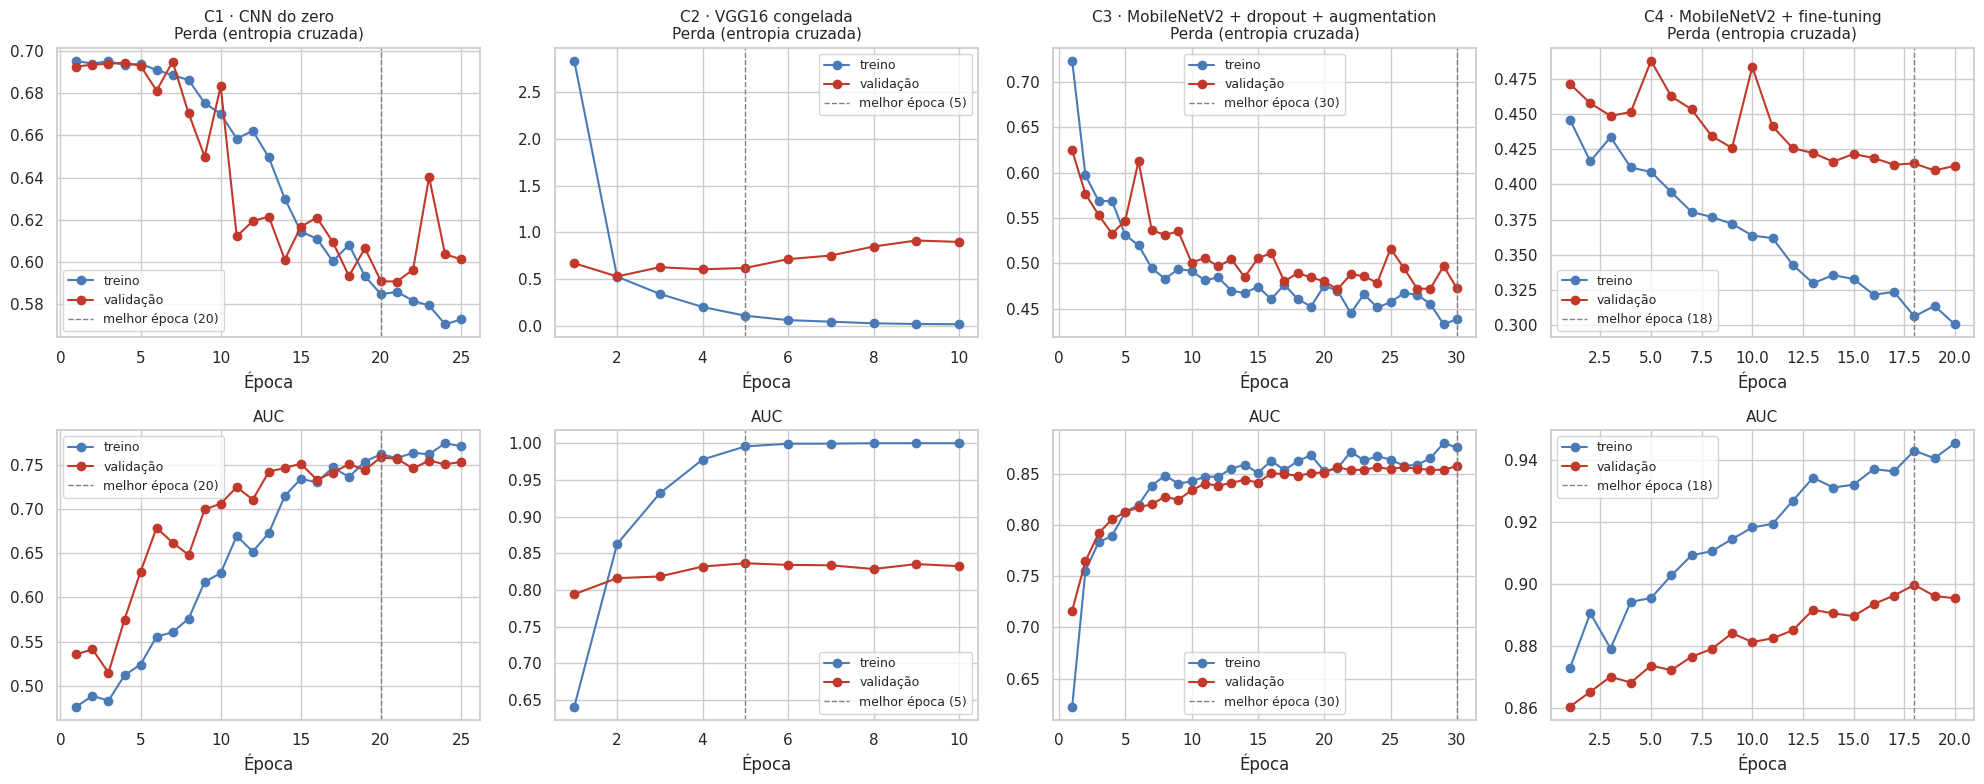

In [12]:
fig, eixos = plt.subplots(2, len(historicos), figsize=(5 * len(historicos), 8), squeeze=False)
for j, (nome, h) in enumerate(historicos.items()):
    epocas = range(1, len(h["loss"]) + 1)
    melhor = resultados[nome]["melhor época"]
    for i, (chave, titulo) in enumerate([("loss", "Perda (entropia cruzada)"), ("auc", "AUC")]):
        eixo = eixos[i, j]
        eixo.plot(epocas, h[chave], "o-", label="treino", color="#4a7bb7")
        eixo.plot(epocas, h[f"val_{chave}"], "o-", label="validação", color="#c0392b")
        eixo.axvline(melhor, color="gray", ls="--", lw=1, label=f"melhor época ({melhor})")
        eixo.set_title(f"{nome}\n{titulo}" if i == 0 else titulo, fontsize=11)
        eixo.set_xlabel("Época")
        eixo.legend(fontsize=9)
plt.tight_layout()
plt.savefig("figuras/03_curvas.png", dpi=130)
plt.show()

In [13]:
comparacao = pd.DataFrame(resultados).T
comparacao["gap treino-validação"] = comparacao["AUC treino"] - comparacao["AUC validação"]
for coluna in ["AUC treino", "AUC validação", "perda validação", "gap treino-validação", "minutos"]:
    comparacao[coluna] = comparacao[coluna].astype(float).round(3)
comparacao = comparacao.sort_values("AUC validação", ascending=False)
NOME_FINAL = comparacao.index[0]
modelo_final = modelos[NOME_FINAL]
print(f"Configuração escolhida (maior AUC na validação): {NOME_FINAL}")
comparacao

Configuração escolhida (maior AUC na validação): C4 · MobileNetV2 + fine-tuning


,épocas rodadas,melhor época,AUC treino,AUC validação,perda validação,minutos,taxa de aprendizado,gap treino-validação
C4 · MobileNetV2 + fine-tuning,20.0,18.0,0.943,0.900,0.415,1.520,0.00001,0.043
C3 · MobileNetV2 + dropout + augmentation,30.0,30.0,0.876,0.858,0.473,2.118,0.00100,0.018
C2 · VGG16 congelada,10.0,5.0,0.996,0.836,0.620,2.257,0.00100,0.159
C1 · CNN do zero,25.0,20.0,0.762,0.758,0.591,1.754,0.00100,0.003


In [14]:
# Leitura automática da comparação: os números mudam a cada treino, a análise acompanha
def leitura_comparacao(tabela):
    linhas = []
    for nome, r in tabela.iterrows():
        gap = r["gap treino-validação"]
        estado = ("overfitting forte (decora o treino)" if gap > 0.10 else
                  "overfitting leve" if gap > 0.04 else "boa generalização")
        linhas.append(f"- {nome}: AUC de validação {r['AUC validação']:.3f}, gap {gap:+.3f} -> {estado}; "
                      f"parou na época {int(r['épocas rodadas'])} (melhor: {int(r['melhor época'])}).")
    c1, c2 = tabela.loc["C1 · CNN do zero"], tabela.loc["C2 · VGG16 congelada"]
    c3, c4 = tabela.loc["C3 · MobileNetV2 + dropout + augmentation"], tabela.loc["C4 · MobileNetV2 + fine-tuning"]
    linhas.append(f"\nTransfer learning vs. do zero: a melhor rede pré-treinada ganhou "
                  f"{max(c2['AUC validação'], c3['AUC validação'], c4['AUC validação']) - c1['AUC validação']:+.3f} de AUC sobre a C1.")
    linhas.append(f"Dropout + augmentation (C3) vs. sem regularização (C2): gap {c3['gap treino-validação']:+.3f} "
                  f"contra {c2['gap treino-validação']:+.3f}.")
    linhas.append(f"Fine-tuning (C4) vs. C3: AUC de validação {c4['AUC validação'] - c3['AUC validação']:+.3f}.")
    return "\n".join(linhas)


print(leitura_comparacao(comparacao))

- C4 · MobileNetV2 + fine-tuning: AUC de validação 0.900, gap +0.043 -> overfitting leve; parou na época 20 (melhor: 18).
- C3 · MobileNetV2 + dropout + augmentation: AUC de validação 0.858, gap +0.018 -> boa generalização; parou na época 30 (melhor: 30).
- C2 · VGG16 congelada: AUC de validação 0.836, gap +0.159 -> overfitting forte (decora o treino); parou na época 10 (melhor: 5).
- C1 · CNN do zero: AUC de validação 0.758, gap +0.003 -> boa generalização; parou na época 25 (melhor: 20).

Transfer learning vs. do zero: a melhor rede pré-treinada ganhou +0.142 de AUC sobre a C1.
Dropout + augmentation (C3) vs. sem regularização (C2): gap +0.018 contra +0.159.
Fine-tuning (C4) vs. C3: AUC de validação +0.042.


**Como ler a comparação:**
- **Gap** é a diferença entre a AUC de treino e a de validação. Um gap grande indica **overfitting**: a rede decorou as fotos de treino e não generaliza. Um gap pequeno com AUC baixa indicaria **underfitting**: a rede é simples demais.
- A **C1**, treinada do zero com poucas fotos, costuma ficar abaixo das redes pré-treinadas. Isso mostra o valor do transfer learning.
- A **C2** (VGG16 com Flatten e uma camada densa grande, sem regularização) tem muitos parâmetros treináveis e tende ao overfitting.
- A **C3** combate esse problema com **dropout**, que desliga 30% dos neurônios a cada passo, e **data augmentation**, que mostra a mesma lesão de jeitos diferentes.
- A **C4** testa se ajustar as camadas mais profundas da rede às fotos de pele traz ganho real.

O **early stopping** aparece nas curvas como a linha tracejada: os pesos guardados são os da melhor época, não os da última. A configuração final é a de **maior AUC na validação**, e o teste só é usado depois dessa escolha.

## 7. Avaliação final no conjunto de teste

### 7.1 Corte de decisão

A pontuação vai de 0 a 1. Na triagem, deixar passar uma lesão que precisava de avaliação é o erro mais grave. Por isso o corte é escolhido **na validação**, nunca no teste: é o maior corte que ainda pega **pelo menos 85%** das lesões que precisavam de avaliação.

Corte escolhido na validação: 0.335

C4 · MobileNetV2 + fine-tuning no TESTE (349 fotos de pacientes que a rede nunca viu):
AUC                       0.858
Acurácia                  0.788
Precisão                  0.824
Recall (sensibilidade)    0.824
Especificidade            0.734
F1-score                  0.824


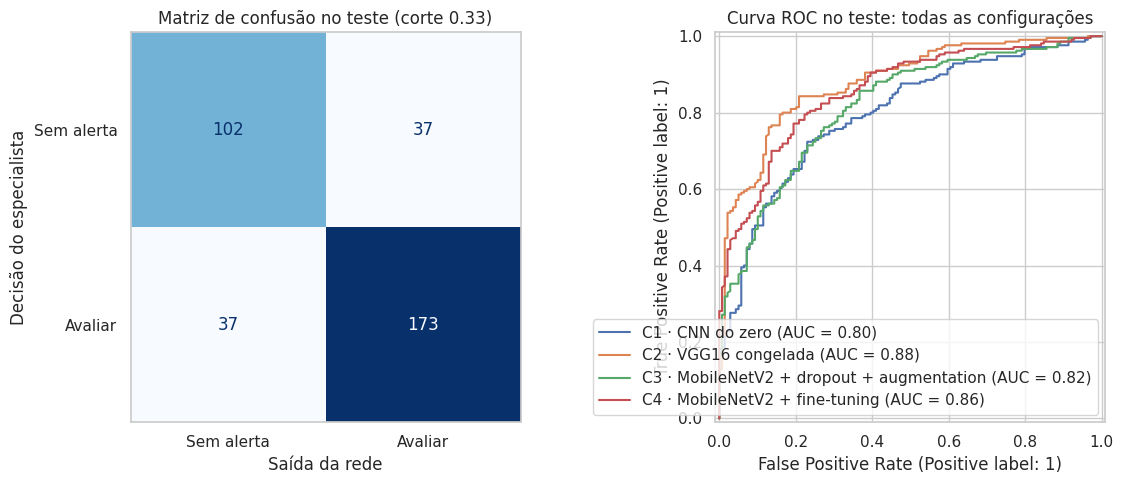

In [15]:
p_val = modelo_final.predict(lotes(X_val, y_val), verbose=0).ravel()
cortes = np.linspace(0.05, 0.95, 181)
recalls = np.array([recall_score(y_val, (p_val >= c).astype(int)) for c in cortes])
CORTE = float(cortes[recalls >= 0.85].max()) if (recalls >= 0.85).any() else 0.5
print(f"Corte escolhido na validação: {CORTE:.3f}")

p_teste = modelo_final.predict(lotes(X_teste, y_teste), verbose=0).ravel()
alerta = (p_teste >= CORTE).astype(int)
metricas_teste = pd.Series({
    "AUC": roc_auc_score(y_teste, p_teste),
    "Acurácia": accuracy_score(y_teste, alerta),
    "Precisão": precision_score(y_teste, alerta),
    "Recall (sensibilidade)": recall_score(y_teste, alerta),
    "Especificidade": recall_score(1 - y_teste, 1 - alerta),
    "F1-score": f1_score(y_teste, alerta),
}).round(3)
print(f"\n{NOME_FINAL} no TESTE ({len(y_teste)} fotos de pacientes que a rede nunca viu):")
print(metricas_teste.to_string())

fig, eixos = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_teste, alerta, display_labels=["Sem alerta", "Avaliar"],
                                        cmap="Blues", values_format="d", ax=eixos[0], colorbar=False)
eixos[0].grid(False)
eixos[0].set_title(f"Matriz de confusão no teste (corte {CORTE:.2f})")
eixos[0].set_xlabel("Saída da rede")
eixos[0].set_ylabel("Decisão do especialista")
for nome, modelo in modelos.items():
    RocCurveDisplay.from_predictions(y_teste, modelo.predict(lotes(X_teste, y_teste), verbose=0).ravel(),
                                     name=nome, ax=eixos[1])
eixos[1].set_title("Curva ROC no teste: todas as configurações")
plt.tight_layout()
plt.savefig("figuras/04_teste.png", dpi=150)
plt.show()

### 7.2 Conferência de segurança

O diagnóstico registrado na base **não foi usado no treino**. Aqui ele serve só para responder a uma pergunta de segurança: entre as lesões de cada tipo no teste, quantas a rede mandou **avaliar com prioridade**? O ideal é que as lesões graves, todas biopsiadas, sejam quase sempre sinalizadas.

In [16]:
seguranca = pd.DataFrame({"diagnóstico registrado": meta.loc[idx_teste, "diagnostic"].to_numpy(), "alerta": alerta})
seguranca = seguranca.groupby("diagnóstico registrado")["alerta"].agg(fotos="size", sinalizadas="sum")
seguranca["% sinalizadas"] = (100 * seguranca["sinalizadas"] / seguranca["fotos"]).round(1)
seguranca.sort_values("% sinalizadas", ascending=False)

,fotos,sinalizadas,% sinalizadas
diagnóstico registrado,,,
BCC,131,115,87.8
SCC,30,26,86.7
MEL,12,7,58.3
ACK,113,45,39.8
NEV,28,11,39.3
SEK,35,6,17.1


In [17]:
graves = [d for d in ("MEL", "BCC", "SCC") if d in seguranca.index]
if graves:
    sinal = seguranca.loc[graves, "sinalizadas"].sum() / seguranca.loc[graves, "fotos"].sum()
    print(f"Lesões registradas como MEL, BCC ou SCC no teste: {100 * sinal:.1f}% receberam 'avaliar com prioridade'.")
leves = [d for d in ("NEV", "SEK") if d in seguranca.index]
if leves:
    sinal = seguranca.loc[leves, "sinalizadas"].sum() / seguranca.loc[leves, "fotos"].sum()
    print(f"Lesões registradas como NEV ou SEK no teste: {100 * sinal:.1f}% receberam 'avaliar com prioridade'.")

Lesões registradas como MEL, BCC ou SCC no teste: 85.5% receberam 'avaliar com prioridade'.
Lesões registradas como NEV ou SEK no teste: 27.0% receberam 'avaliar com prioridade'.


**Leitura:** a tabela mostra, para cada tipo de lesão registrado, a parte que a rede mandou avaliar. A expectativa de segurança é que as lesões dos tipos mais graves sejam **quase sempre sinalizadas**, e que as lesões comuns e benignas, como a pinta (NEV) e a ceratose seborreica (SEK), sejam sinalizadas menos vezes. Os casos graves que **não** foram sinalizados são o erro mais importante do modelo. Por isso:
1. a mensagem de "sem alerta" **nunca tranquiliza** a pessoa;
2. o PulsoVision sempre orienta a procurar a UBS se a lesão mudar, crescer, coçar ou sangrar.

## 8. Demonstração da aplicação

### 8.1 Fotos que a rede nunca viu

As fotos abaixo são do **conjunto de teste**: pacientes que não participaram do treino, da validação nem da escolha do corte. Para cada uma aparecem a entrada (a foto), a saída da rede (a pontuação) e a mensagem que o PulsoVision mostraria ao cidadão.

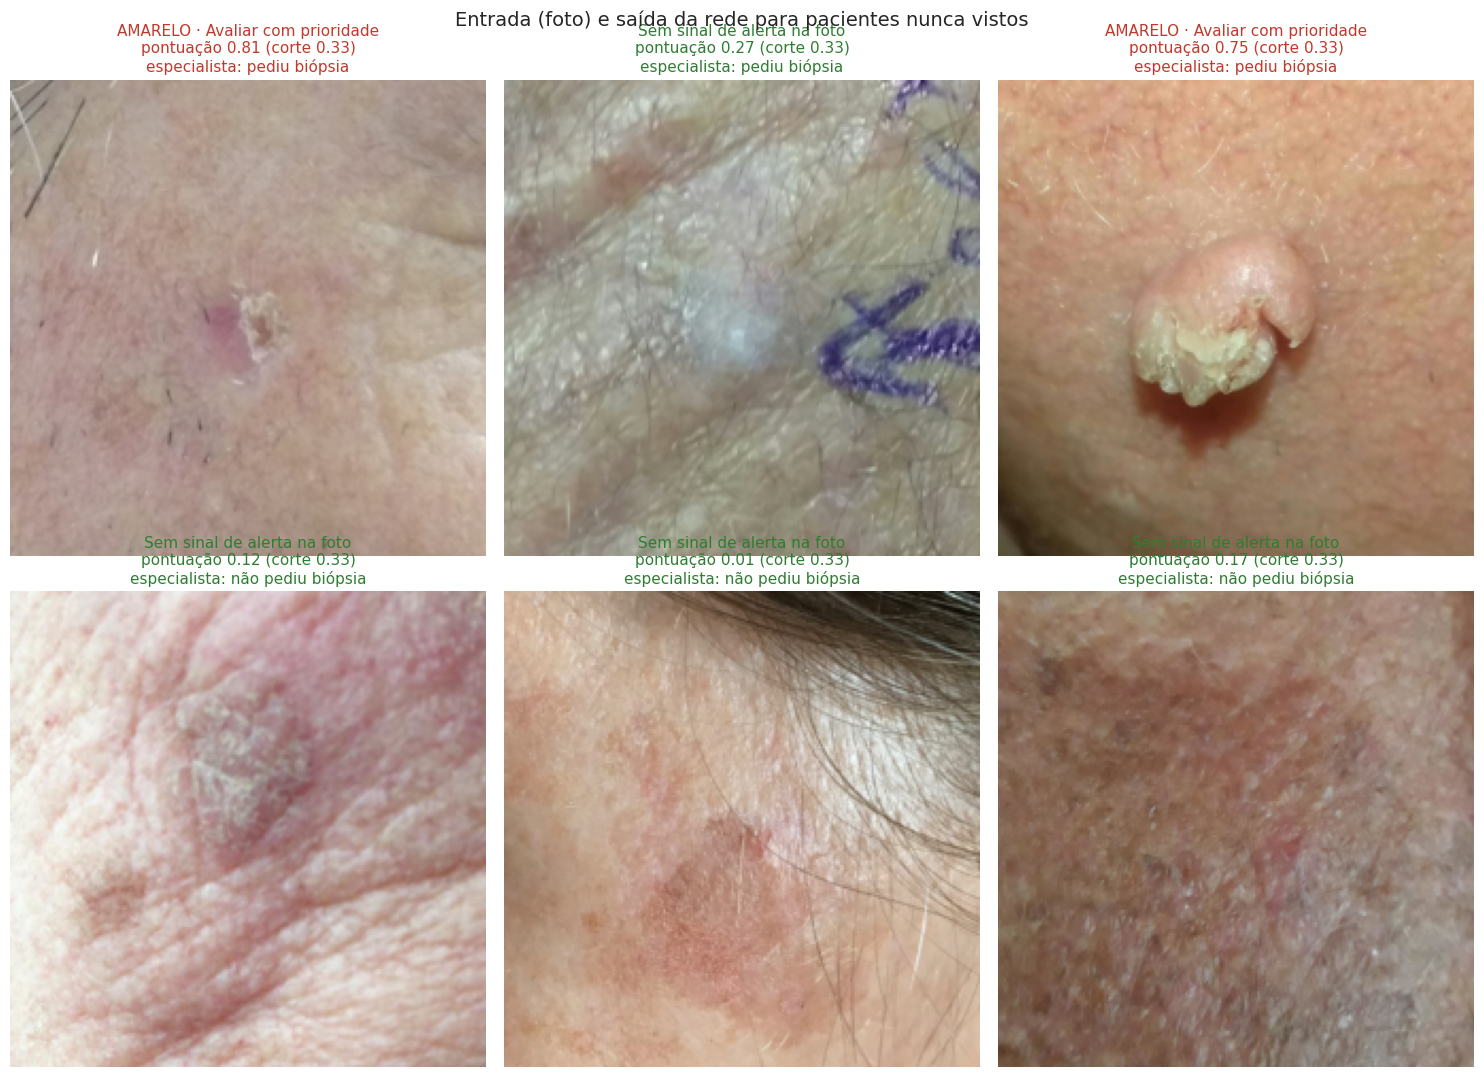

In [18]:
MENSAGENS = {
    1: ("AMARELO · Avaliar com prioridade",
        "A foto mostra sinais que merecem avaliação. Procure a UBS esta semana e mostre esta lesão."),
    0: ("Sem sinal de alerta na foto",
        "Isso não descarta nada. Se a lesão crescer, mudar de cor, coçar ou sangrar, procure a UBS."),
}


def avaliar_foto(imagem_rgb: np.ndarray) -> dict:
    """Recebe uma foto (já recortada em 224 x 224) e devolve o que o app mostraria. Nunca diagnostica."""
    pontuacao = float(modelo_final(imagem_rgb[None].astype("float32"), training=False)[0, 0])
    decisao = int(pontuacao >= CORTE)
    titulo, texto = MENSAGENS[decisao]
    return {"pontuação": round(pontuacao, 3), "sinal_foto": "suspeito" if decisao else "sem alerta",
            "título": titulo, "mensagem": texto}


rng = np.random.default_rng(SEMENTE)
escolhidas = np.concatenate([rng.choice(np.where(y_teste == 1)[0], 3, replace=False),
                             rng.choice(np.where(y_teste == 0)[0], 3, replace=False)])
fig, eixos = plt.subplots(2, 3, figsize=(15, 11))
for eixo, i in zip(eixos.ravel(), escolhidas):
    r = avaliar_foto(X_teste[i])
    eixo.imshow(X_teste[i])
    eixo.axis("off")
    cor = "#c0392b" if r["sinal_foto"] == "suspeito" else "#2e7d32"
    eixo.set_title(f"{r['título']}\npontuação {r['pontuação']:.2f} (corte {CORTE:.2f})\n"
                   f"especialista: {'pediu biópsia' if y_teste[i] else 'não pediu biópsia'}", color=cor, fontsize=11)
plt.suptitle("Entrada (foto) e saída da rede para pacientes nunca vistos", fontsize=14)
plt.tight_layout()
plt.savefig("figuras/05_demonstracao.png", dpi=120)
plt.show()

### 8.2 Integração com o PulsoVision

No app, a CNN é uma peça da triagem. A função abaixo junta as três fontes de informação que o PulsoVision usa:
- a **triagem por regras** (inspirada no protocolo de Manchester), feita a partir do que o cidadão conta;
- a **foto**, avaliada por esta CNN;
- o **encaminhamento**, que no produto final usa o modelo de vazio de urgência (disciplina 06) e a fila medida pelo totem (disciplinas 01 a 04).

A regra que nunca quebra: **a foto só pode subir a cor, nunca baixar**, e sinais de alarme vão direto para o vermelho.

In [19]:
SINAIS_VERMELHOS = {"sangramento_intenso": "sangramento que não para", "febre_alta": "febre alta com a ferida",
                    "dor_forte": "dor forte"}


def triagem_pulso(relato: dict, imagem_rgb=None) -> dict:
    """Relato do cidadão + foto da lesão -> cor da triagem e orientação. A IA não diagnostica."""
    alarmes = [texto for chave, texto in SINAIS_VERMELHOS.items() if relato.get(chave)]
    foto = avaliar_foto(imagem_rgb) if imagem_rgb is not None else None
    if alarmes:
        cor, orientacao = "VERMELHO", "Vá agora à urgência mais perto (" + ", ".join(alarmes) + ")."
    elif (foto and foto["sinal_foto"] == "suspeito") or relato.get("mudou_de_cor") or relato.get("cresceu"):
        cor, orientacao = "AMARELO", "Procure a UBS esta semana e mostre a lesão."
    else:
        cor, orientacao = "VERDE", ("Sem sinal de alerta agora. Se a lesão crescer, mudar de cor, coçar ou sangrar, "
                                    "procure a UBS.")
    return {"cor": cor, "foto": foto["título"] if foto else "sem foto",
            "pontuação da foto": foto["pontuação"] if foto else None, "orientação": orientacao}


casos = {
    "Seu Antônio, 67 anos, ferida no rosto que não cicatriza (com foto)": ({}, X_teste[escolhidas[0]]),
    "Júlia, 25 anos, pinta antiga, sem mudança (com foto)": ({}, X_teste[escolhidas[3]]),
    "Dona Lúcia, 58 anos, lesão que cresceu (sem foto)": ({"cresceu": True}, None),
    "Seu Carlos, 71 anos, lesão sangrando muito (com foto)": ({"sangramento_intenso": True}, X_teste[escolhidas[1]]),
}
pd.DataFrame({nome: triagem_pulso(relato, imagem) for nome, (relato, imagem) in casos.items()}).T

,cor,foto,pontuação da foto,orientação
"Seu Antônio, 67 anos, ferida no rosto que não cicatriza (com foto)",AMARELO,AMARELO · Avaliar com prioridade,0.807,Procure a UBS esta semana e mostre a lesão.
"Júlia, 25 anos, pinta antiga, sem mudança (com foto)",VERDE,Sem sinal de alerta na foto,0.124,"Sem sinal de alerta agora. Se a lesão crescer,..."
"Dona Lúcia, 58 anos, lesão que cresceu (sem foto)",AMARELO,sem foto,None,Procure a UBS esta semana e mostre a lesão.
"Seu Carlos, 71 anos, lesão sangrando muito (com foto)",VERMELHO,Sem sinal de alerta na foto,0.265,Vá agora à urgência mais perto (sangramento qu...


In [20]:
modelo_final.save("cnn_prioridade_pele.keras")
pd.Series({"configuracao": NOME_FINAL, "corte": CORTE, "tamanho_entrada": TAMANHO}).to_json("cnn_config.json")
print(f"Modelo salvo: cnn_prioridade_pele.keras ({NOME_FINAL}) | corte {CORTE:.3f} em cnn_config.json")

Modelo salvo: cnn_prioridade_pele.keras (C4 · MobileNetV2 + fine-tuning) | corte 0.335 em cnn_config.json


## Resultados desta execução (GPU T4, semente 2026)

**Comparativo das quatro configurações (validação):**

| Config. | AUC validação | Gap treino − validação | Diagnóstico do treino |
|---|---|---|---|
| C1 · CNN do zero | 0,758 | +0,003 | **Generaliza, mas aprende pouco (underfitting)**. O gap quase zero faz a leitura automática da seção 6 marcar “boa generalização”, mas a AUC é a mais baixa das quatro: a rede é simples demais para 1,6 mil fotos de treino |
| C2 · VGG16 congelada (aula) | 0,836 | +0,159 | **Overfitting forte**: AUC de treino perto de 1,0 já na época 6, enquanto a validação parou em 0,84. O early stopping guardou a época 5 |
| C3 · MobileNetV2 + dropout + augmentation | 0,858 | +0,018 | **Boa generalização**. A melhor época foi a última (30), sinal de que ainda havia espaço para aprender |
| **C4 · MobileNetV2 + fine-tuning** | **0,900** | +0,043 | **Escolhida**. Overfitting leve, dentro do aceitável |

**O que os números mostram:**
1. **Transfer learning vale a pena:** a melhor rede pré-treinada ganhou **+0,142 de AUC** sobre a CNN treinada do zero.
2. **A regularização funciona:** com dropout e data augmentation, o gap caiu de 0,159 (C2) para 0,018 (C3), cerca de 9 vezes menor, e a AUC de validação ainda subiu.
3. **O fine-tuning fecha o ganho:** liberar as últimas camadas da MobileNetV2 com taxa de aprendizado 10⁻⁵ somou **+0,042 de AUC** sobre a C3, com aumento pequeno do gap.

**Corte e segurança (conjunto de teste):**
- O corte escolhido na validação foi **0,335**. Ele é baixo de propósito, porque o objetivo era pegar pelo menos 85% das lesões que precisavam de avaliação.
- Entre as lesões registradas como **MEL, BCC ou SCC** no teste, **85,5%** receberam "avaliar com prioridade".
- Entre as lesões comuns e benignas (**NEV e SEK**), só **27,0%** receberam alerta. A rede separa bem os dois grupos sem nunca ter visto o diagnóstico.
- Cerca de **1 em cada 7 lesões graves não foi sinalizada pela foto**. Esse é o motivo de três regras do PulsoVision: a mensagem "sem alerta" nunca tranquiliza, a foto só sobe a cor (nunca baixa) e o relato da pessoa ("cresceu", "mudou de cor", "sangra") leva ao amarelo ou ao vermelho mesmo sem alerta na foto.

## 9. Documentação: decisões, resultados, limitações e evolução

**Decisões técnicas:**

| Decisão | Por quê |
|---|---|
| Alvo = "o especialista pediu biópsia" | Mantém a regra do PulsoVision de que a IA nunca diagnostica: a rede aprende **o que vale investigar**, não qual é a doença. As classes também ficam mais equilibradas do que nos 6 diagnósticos (o melanoma tem poucas fotos) |
| Divisão por paciente | Evita que a rede "reconheça a pessoa" no teste e infle as métricas |
| Transfer learning | Com cerca de 2,3 mil fotos, treinar do zero tende ao overfitting; redes pré-treinadas já sabem extrair bordas, cores e texturas |
| MobileNetV2 como candidata | É leve e foi feita para celular, que é onde o PulsoVision roda |
| Dropout, augmentation e early stopping | Reduzem o overfitting e guardam os pesos da melhor época |
| Corte com recall de pelo menos 85% na validação | Na triagem, perder uma lesão que precisava de avaliação é pior que um alerta a mais |

**Limitações:**
- **O rótulo é uma decisão clínica, não a verdade absoluta.** Lesões não biopsiadas tiveram diagnóstico por consenso de dermatologistas. Outro médico poderia decidir diferente.
- **Fotos de uma única região do Brasil** (Espírito Santo) e de um único serviço. Peles, aparelhos e iluminação diferentes podem piorar o desempenho.
- **A qualidade da foto importa:** foco, luz e distância variam muito no celular, e a rede não avalia se a foto ficou boa.
- **A rede pode errar nos dois sentidos.** Por isso ela só sobe a cor, a mensagem de "sem alerta" nunca tranquiliza e o exame presencial continua obrigatório.

**Possibilidades de evolução:**
- checar a qualidade da foto antes de avaliar (pedir outra se estiver borrada ou escura);
- combinar a foto com as respostas da pessoa (cresceu, coça, sangra?), que também existem na base;
- ampliar a base com fotos de outras regiões e tons de pele;
- **calibrar** a pontuação;
- testar com dermatologistas de uma UBS antes de qualquer uso real.